In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib.ticker import ScalarFormatter
%matplotlib inline
import pandas as pd
from planet_cookbook import read_reports as rr
import os
import rebound
import seaborn as sns

sol_to_earth = 332946.078
G = 6.6743* 10**(-11) #N⋅m2/kg2
M_sun = 1.989e+33 #g
AU = 1.496e+13 #cm

params = {
   'axes.labelsize': 15,
   'font.size': 15,
   'legend.fontsize': 10,
   'xtick.labelsize': 15,
   'ytick.labelsize': 15,
   'text.usetex': True, #to use TeX in your labels
   'font.family':'serif',
   'axes.titlesize': 15
   }
rcParams.update(params)

vib_blue = "#0C7BDC"
teal = "#40B0A6"
purple = "#5D3A9B" 

In [2]:
base_path = "/Users/honeyeah/Codes/data/" #folder with all data

sim_set = "merger/" #name of simulation set, folder with subfolders the name "sim_set_i"
sim_archive_path = base_path + sim_set + "merger_" #path given to get_runtime_data function
merger_reb_rdf = rr.get_runtime_data(sim_archive_path, 10, "merger_") #rdf is runtime data frame

/Users/honeyeah/miniconda3/envs/haniyeh_research/lib/python3.13/site-packages/rebound/simulationarchive.py:103: RuntimeWarning: Binary file was saved with a different version of REBOUND. Binary format might have changed. Binary file was saved with REBOUND Version 4.4.10. You are currently using REBOUND Version 4.4.11.
  warnings.warn(message, RuntimeWarning)
/Users/honeyeah/miniconda3/envs/haniyeh_research/lib/python3.13/site-packages/rebound/simulationarchive.py:150: RuntimeWarning: Binary file was saved with a different version of REBOUND. Binary format might have changed.
  warnings.warn(message, RuntimeWarning)
/Users/honeyeah/miniconda3/envs/haniyeh_research/lib/python3.13/site-packages/rebound/simulationarchive.py:150: RuntimeWarning: You have to reset function pointers after creating a reb_simulation struct with a binary file.
  warnings.warn(message, RuntimeWarning)


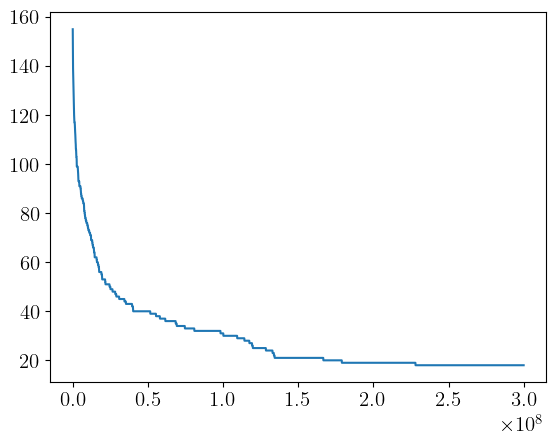

In [3]:
for i in range(1):
    sim = merger_reb_rdf[merger_reb_rdf['simulation_id'] == i+1]
    plt.plot(sim['time'], sim['N_bodies'])

plt.show()

In [4]:
sim1 = merger_reb_rdf[merger_reb_rdf['simulation_id']==1]

# GENGA output reading

In [5]:
genga_dt = 6
time_interval = 1e5 * 365
timestep_interval = time_interval/genga_dt
timestep_interval =  int(timestep_interval)
print("n timesteps in the interval = ", int(timestep_interval))

n timesteps in the interval =  6083333


In [6]:
6083333 * 6 / 365 / 1e5

0.9999999452054794

In [21]:
path = '/Users/honeyeah/Codes/data/merger_gengas/merger_genga_1/'
colnames = ['time', 'i', 'a', 'e', 'inc',
            'Omega', 'w', 'Theta', 'E', 'M', 'm', 'r']

# Generate the filenames at intervals of 1e7
file_indices = list(range(0, 18249999,  timestep_interval))
filenames = [f"aeimerger_1_{i:012d}.dat" for i in file_indices]

In [22]:
frames = np.linspace(0,len(file_indices), len(file_indices) + 1)

In [23]:
genga_dfs = []
genga_n_bodies = []
genga_times = []
for i in range(len(file_indices)):
    filepath = os.path.join(path, filenames[i])
    df = pd.read_csv(filepath, sep=r"\s+", names=colnames, header=None)
    genga_dfs.append(df)
    genga_n_bodies.append(len(df))

In [24]:
genga_dfs[1]

,time,i,a,e,inc,Omega,w,Theta,E,M,m,r
0,99931.548255,150,1.830994,0.051800,0.016025,1.462973,1.666136,0.055049,0.052269,0.049563,2.800000e-08,0.000013
1,99931.548255,0,0.727548,0.025430,0.011877,0.543870,2.894737,2.699133,2.688116,2.676975,5.880000e-07,0.000035
2,99931.548255,2,0.716076,0.022265,0.025779,3.540372,2.842187,5.777255,5.787943,5.798524,2.800000e-07,0.000027
3,99931.548255,153,2.026006,0.043352,0.004140,4.521962,4.809189,1.949120,1.908495,1.867591,2.800000e-08,0.000013
4,99931.548255,3,0.610181,0.005249,0.000786,0.221876,6.165805,3.651602,3.654170,3.656745,6.160000e-07,0.000035
...,...,...,...,...,...,...,...,...,...,...,...,...
125,99931.548255,125,1.784186,0.014303,0.014658,4.573471,3.811868,0.432411,0.426456,0.420540,2.800000e-08,0.000013
126,99931.548255,126,1.786381,0.011002,0.022951,3.499791,0.892323,2.488669,2.481956,2.475214,2.800000e-08,0.000013
127,99931.548255,127,1.702801,0.024154,0.038282,3.979429,0.253319,3.030114,3.027394,3.024642,2.800000e-08,0.000013
128,99931.548255,128,1.797693,0.068941,0.014048,5.077727,3.827626,5.093719,5.156952,5.219192,2.800000e-08,0.000013


In [25]:
genga_n_bodies

[154, 130, 121]

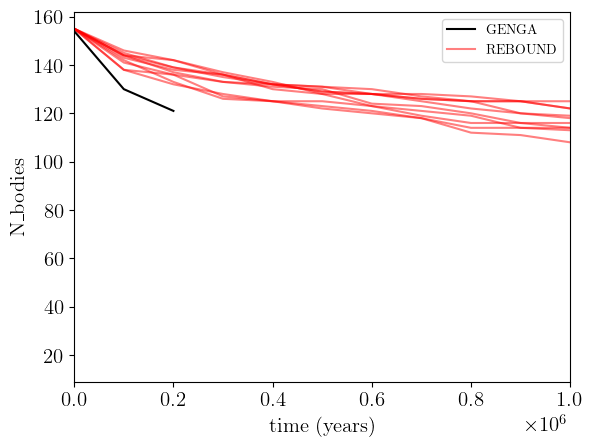

In [28]:
time = np.array(file_indices) * (6/365)
plt.plot(time, genga_n_bodies, label = 'GENGA', color = 'black')
for i in range(10):
    sim = merger_reb_rdf[merger_reb_rdf['simulation_id'] == i+1]
    if i == 2:
        plt.plot(sim['time'], sim['N_bodies'], label = 'REBOUND', color='red', alpha = 0.5)
    else:
        plt.plot(sim['time'], sim['N_bodies'], color = 'red', alpha = 0.5)

plt.xlim(0,0.1e7)
plt.xlabel('time (years)')
plt.ylabel('N_bodies')
plt.legend()
plt.show()

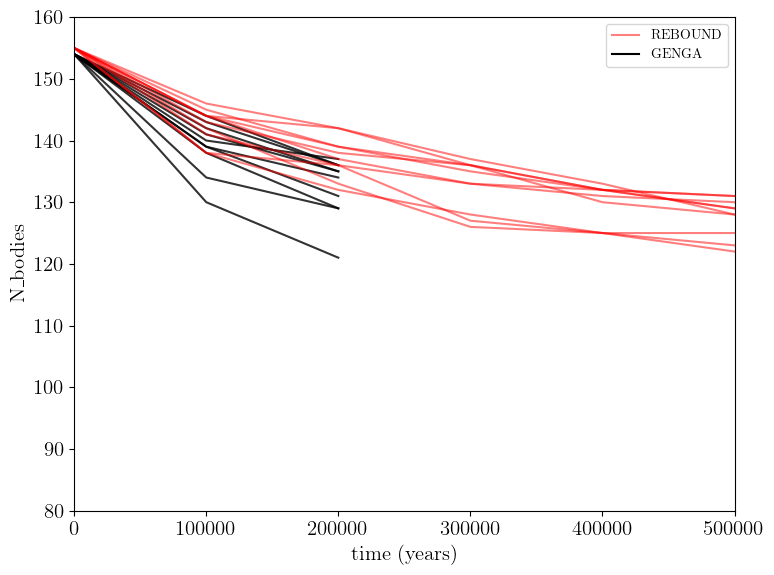

In [35]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

base_path = '/Users/honeyeah/Codes/data/merger_gengas'

colnames = ['time', 'i', 'a', 'e', 'inc',
            'Omega', 'w', 'Theta', 'E', 'M', 'm', 'r']

# file indices (same for all runs)
file_indices = list(range(0, 18249999, timestep_interval))
frames = np.linspace(0, len(file_indices), len(file_indices) + 1)

# store outputs if you want them later
all_genga_n_bodies = {}
all_genga_times = {}

plt.figure(figsize=(8,6))

for sim_id in range(1, 11):
    path = os.path.join(base_path, f'merger_genga_{sim_id}')
    filenames = [f"aeimerger_{sim_id}_{i:012d}.dat" for i in file_indices]

    genga_n_bodies = []

    for i in range(len(file_indices)):
        filepath = os.path.join(path, filenames[i])
        df = pd.read_csv(filepath, sep=r"\s+", names=colnames, header=None)
        genga_n_bodies.append(len(df))

    time = np.array(file_indices) * (6 / 365)

    all_genga_n_bodies[sim_id] = np.array(genga_n_bodies)
    all_genga_times[sim_id] = time

    plt.plot(time, genga_n_bodies, color='black', alpha=0.8)

# ---- REBOUND comparison ----
for i in range(10):
    sim = merger_reb_rdf[merger_reb_rdf['simulation_id'] == i+1]
    if i == 2:
        plt.plot(sim['time'], sim['N_bodies'],
                 label='REBOUND', color='red', alpha=0.5)
    else:
        plt.plot(sim['time'], sim['N_bodies'],
                 color='red', alpha=0.5)

plt.plot([], [], color='black', label='GENGA')  # legend handle
plt.xlim(0, 0.5e6)
plt.ylim(80,160)
plt.xlabel('time (years)')
plt.ylabel('N_bodies')
plt.legend()
plt.tight_layout()
plt.show()


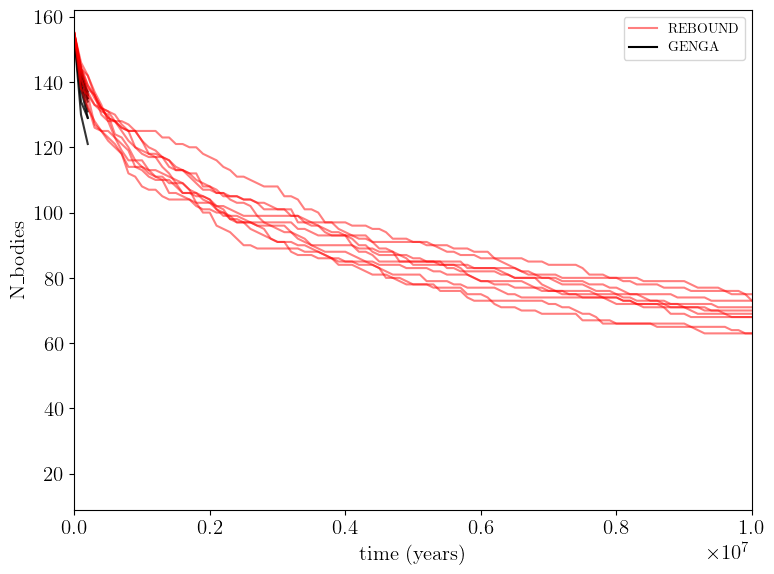

In [37]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

base_path = '/Users/honeyeah/Codes/data/merger_gengas'

colnames = ['time', 'i', 'a', 'e', 'inc',
            'Omega', 'w', 'Theta', 'E', 'M', 'm', 'r']

# file indices (same for all runs)
file_indices = list(range(0, 18249999, timestep_interval))
frames = np.linspace(0, len(file_indices), len(file_indices) + 1)

# store outputs if you want them later
all_genga_n_bodies = {}
all_genga_times = {}

plt.figure(figsize=(8,6))

for sim_id in range(1, 11):
    path = os.path.join(base_path, f'merger_genga_{sim_id}')
    filenames = [f"aeimerger_{sim_id}_{i:012d}.dat" for i in file_indices]

    genga_n_bodies = []

    for i in range(len(file_indices)):
        filepath = os.path.join(path, filenames[i])
        df = pd.read_csv(filepath, sep=r"\s+", names=colnames, header=None)
        genga_n_bodies.append(len(df))

    time = np.array(file_indices) * (6 / 365)

    all_genga_n_bodies[sim_id] = np.array(genga_n_bodies)
    all_genga_times[sim_id] = time

    plt.plot(time, genga_n_bodies, color='black', alpha=0.8)

# ---- REBOUND comparison ----
for i in range(10):
    sim = merger_reb_rdf[merger_reb_rdf['simulation_id'] == i+1]
    if i == 2:
        plt.plot(sim['time'], sim['N_bodies'],
                 label='REBOUND', color='red', alpha=0.5)
    else:
        plt.plot(sim['time'], sim['N_bodies'],
                 color='red', alpha=0.5)

plt.plot([], [], color='black', label='GENGA')  # legend handle
plt.xlim(0, 10e6)
plt.xlabel('time (years)')
plt.ylabel('N_bodies')
plt.legend()
plt.tight_layout()
plt.show()
